Домашнее задание №3.

Самостоятельно реализовать архитектуру нейронной сети (на любом фреймфорке) для CF. На вход получает 2 бинарных вектора items и users.  На выход предсказываете рейтинг объекта.
1.  Использовать 3 полносвязанных слоев.
2.  Использовать 5 полносвязанных слоев.


Для каждой сети выбрать оптимальную функцию активации (по кросс-валидации) по метрике RMSE. Также можно попробовать оптимизировать другие параметры.

Сравнить качество 1-ой и 2-ой сети.

В качестве обучающего датасэта можно использовать любой, но рекомендуется использовать датасэт REKKO https://boosters.pro/championship/rekko_challenge/data (ranking.csv).

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

### Чтение данных

In [ ]:
df = pd.read_csv('ratings.csv', names=['user', 'item', 'rating', 'ts'],   skiprows=1)

In [ ]:
df.head()

,user,item,rating,ts
0,571252,1364,10,4.430517e+07
1,63140,3037,10,4.430514e+07
2,443817,4363,8,4.430514e+07
3,359870,1364,10,4.430506e+07
4,359870,3578,9,4.430506e+07


In [ ]:
item_mapping = dict(zip(df.item.unique(), range(df.item.nunique())))

In [ ]:
user_mapping = dict(zip(df.user.unique(), range(df.user.nunique())))

In [ ]:
df.user = df.user.map(user_mapping)
df.item = df.item.map(item_mapping)

In [ ]:
ITEM_COUNT = df.item.nunique()
USER_COUNT = df.user.nunique()

In [ ]:
item = df.item.values.reshape((-1, 1))
user = df.user.values.reshape((-1, 1))
target = df.rating.values.reshape((-1, 1))

### Архитектура нейронной сети

In [ ]:
item_inputs = keras.Input(shape=(1, ),  name='item')
user_inputs = keras.Input(shape=(1, ),  name='user')

item_features = layers.Embedding(ITEM_COUNT, 64)(item_inputs)
user_features = layers.Embedding(USER_COUNT, 64)(user_inputs)

x = layers.concatenate([item_features, user_features])
x = layers.Dense(32,  activation='relu')(x)
x = layers.Dense(16, activation='relu')(x)
x = layers.Dense(4, activation='relu')(x)
rating = layers.Dense(1, name="rating")(x)

# Instantiate an end-to-end model predicting both priority and department
model = keras.Model(inputs=[item_inputs, user_inputs],
                    outputs=[rating],
                    name='NCF'
                   )

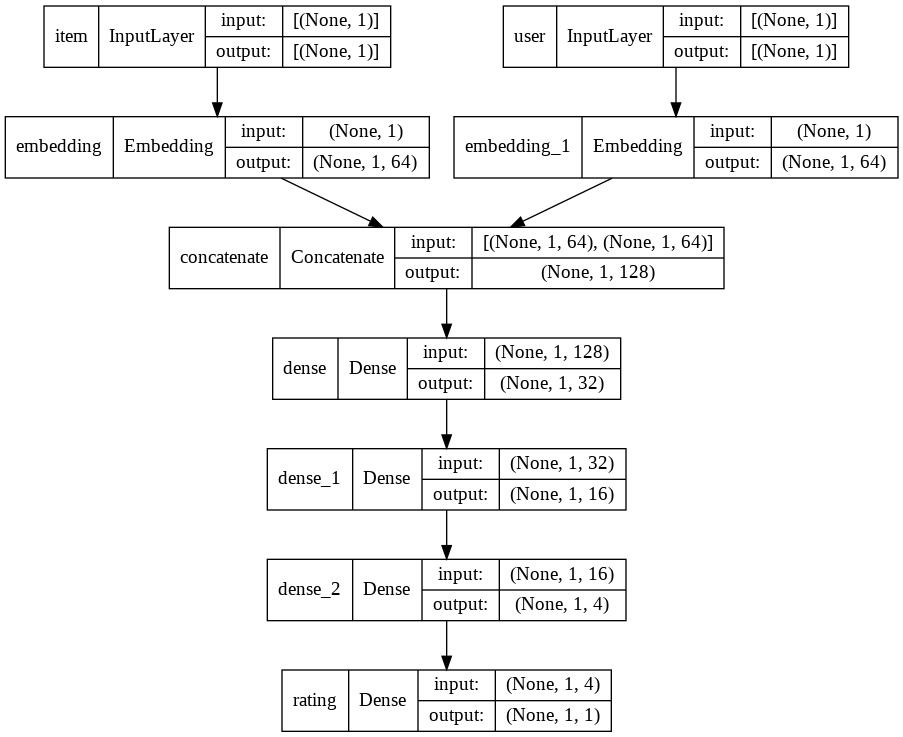

In [ ]:
keras.utils.plot_model(model, "NCF.png",  show_shapes=True)

In [ ]:
model.compile(
              loss=keras.losses.MeanAbsoluteError(),
              optimizer=keras.optimizers.RMSprop(),
              metrics=[keras.metrics.RootMeanSquaredError(name='rmse')],
             )

In [ ]:
history = model.fit({'item': item, 'user': user},
                    {'rating': target}, 
                    batch_size=256, 
                    epochs=2,
                    validation_split=0.33)

Epoch 1/2
1149/1149 [==============================] - 40s 34ms/step - loss: 1.9263 - rmse: 2.8723 - val_loss: 1.3583 - val_rmse: 1.9279
Epoch 2/2
1149/1149 [==============================] - 42s 36ms/step - loss: 1.2089 - rmse: 1.8080 - val_loss: 1.3365 - val_rmse: 1.9358


### Предсказание средним 

In [ ]:
from sklearn.metrics import mean_squared_error

In [ ]:
train = df.iloc[:300000, :]
test = df.iloc[300000:, :]

In [ ]:
na = train.rating.mean()

In [ ]:
x = pd.merge(test, train.groupby('user').rating.mean(), on=['user'], how='left', suffixes=('', '_pred'))[['rating','rating_pred']]
x.rating_pred.fillna(na, inplace=True)
mean_squared_error(x.rating, x.rating_pred,  squared=False)

2.120281197319447

In [ ]:
x = pd.merge(test, train.groupby('item').rating.mean(), on=['item'], how='left', suffixes=('', '_pred'))[['rating','rating_pred']]
x.rating_pred.fillna(na, inplace=True)
mean_squared_error(x.rating, x.rating_pred,  squared=False)

1.9167841499886167

In [ ]:
np.sqrt(np.mean((test.rating.values - na)**2))

2.0478917505648355

Предсказания сети получаются на уровне предсказания средним рейтингом фильма на обучающей выборке.

### Вариант с 5 слоями

In [ ]:
item_inputs = keras.Input(shape=(1, ),  name='item')
user_inputs = keras.Input(shape=(1, ),  name='user')

item_features = layers.Embedding(ITEM_COUNT, 128)(item_inputs)
user_features = layers.Embedding(USER_COUNT, 128)(user_inputs)

x = layers.concatenate([item_features, user_features])
x = layers.Dense(64,  activation='relu')(x)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(16, activation='relu')(x)
x = layers.Dense(8, activation='relu')(x)
x = layers.Dense(4, activation='relu')(x)
rating = layers.Dense(1, name="rating")(x)

# Instantiate an end-to-end model predicting both priority and department
model = keras.Model(inputs=[item_inputs, user_inputs],
                    outputs=[rating],
                    name='NCF'
                   )

In [ ]:
model.compile(
              loss=keras.losses.MeanAbsoluteError(),
              optimizer=keras.optimizers.Adam(),
              metrics=[keras.metrics.RootMeanSquaredError(name='rmse')],
             )

In [ ]:
history = model.fit({'item': item, 'user': user},
                    {'rating': target}, 
                    batch_size=256, 
                    epochs=4,
                    validation_split=0.33)

Epoch 1/4
1149/1149 [==============================] - 179s 154ms/step - loss: 1.8239 - rmse: 2.8018 - val_loss: 1.3395 - val_rmse: 1.9086
Epoch 2/4
1149/1149 [==============================] - 178s 155ms/step - loss: 1.1411 - rmse: 1.7415 - val_loss: 1.3352 - val_rmse: 1.9172
Epoch 3/4
1149/1149 [==============================] - 178s 155ms/step - loss: 1.0094 - rmse: 1.6105 - val_loss: 1.3472 - val_rmse: 1.9561
Epoch 4/4
1149/1149 [==============================] - 178s 155ms/step - loss: 0.9352 - rmse: 1.5251 - val_loss: 1.3431 - val_rmse: 1.9521


### Архитектура со слоем мультипликации (GMF)

$y = \sum_k w_k{p_{user}}_k{p_{item}}_k$

Скалярное произведение эмбедингов пользователя $p_{user}$ и товара $p_{item}$ с весами. 

Добавлена регуляризация слоя эмбедингов.

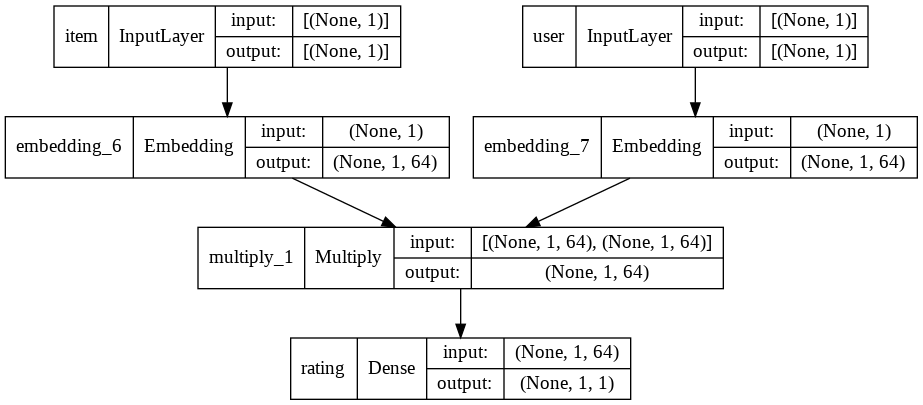

In [ ]:
item_inputs = keras.Input(shape=(1, ),  name='item')
user_inputs = keras.Input(shape=(1, ),  name='user')

item_features = layers.Embedding(ITEM_COUNT, 64, embeddings_regularizer=keras.regularizers.l1(1e-4))(item_inputs)
user_features = layers.Embedding(USER_COUNT, 64, embeddings_regularizer=keras.regularizers.l1(1e-4))(user_inputs)

x = layers.Multiply()([item_features, user_features])
rating = layers.Dense(1, name="rating")(x)

# Instantiate an end-to-end model predicting both priority and department
model = keras.Model(inputs=[item_inputs, user_inputs],
                    outputs=[rating],
                    name='NCF'
                   )

model.compile(
              loss=keras.losses.MeanAbsoluteError(),
              optimizer=keras.optimizers.Adam(),
              metrics=[keras.metrics.RootMeanSquaredError(name='rmse')],
             )

keras.utils.plot_model(model, "NCF.png",  show_shapes=True)

In [ ]:
history = model.fit({'item': item, 'user': user},
                    {'rating': target}, 
                    batch_size=256, 
                    epochs=20,
                    validation_split=0.33)

Epoch 1/20
1149/1149 [==============================] - 101s 87ms/step - loss: 7.9803 - rmse: 7.8897 - val_loss: 7.1622 - val_rmse: 7.3605
Epoch 2/20
1149/1149 [==============================] - 103s 90ms/step - loss: 6.5591 - rmse: 6.7940 - val_loss: 6.0511 - val_rmse: 6.2791
Epoch 3/20
1149/1149 [==============================] - 99s 86ms/step - loss: 5.4872 - rmse: 5.7374 - val_loss: 4.9945 - val_rmse: 5.2349
Epoch 4/20
1149/1149 [==============================] - 99s 86ms/step - loss: 4.4637 - rmse: 4.7183 - val_loss: 4.0128 - val_rmse: 4.2476
Epoch 5/20
1149/1149 [==============================] - 100s 87ms/step - loss: 3.5512 - rmse: 3.7836 - val_loss: 3.1432 - val_rmse: 3.3530
Epoch 6/20
1149/1149 [==============================] - 99s 86ms/step - loss: 2.7635 - rmse: 2.9736 - val_loss: 2.4495 - val_rmse: 2.6345
Epoch 7/20
1149/1149 [==============================] - 99s 86ms/step - loss: 2.1741 - rmse: 2.3911 - val_loss: 1.9473 - val_rmse: 2.1785
Epoch 8/20
1149/1149 [=========

C 9-ой эпохи начинается переобучение

### Выводы

1. Качество предсказаний на таком объеме данных для всех исследованных архетектур нейронных сетей не превышает тривиального предсказания средним рейтингом фильма на обучающей выборке. 
2. Cеть с 5 слоями лучше, чем сеть с 3 в третьем знаке. С практической точки зрения разницы нет. 
3. От подбора функций активации значительного value так же не замечено: сигмоида, гиперболический тангенс приводят к увеличению времени обучения моделей. 

### Сравнение с KNN

In [1]:
!pip install scikit-surprise

     |████████████████████████████████| 11.8 MB 10.5 MB/s 
  Created wheel for scikit-surprise: filename=scikit_surprise-1.1.1-cp37-cp37m-linux_x86_64.whl size=1619418 sha256=d7f5e87360b0f811f683b9e38ac493ba7b1a51b1600491d4f7f43be8134a0d2f
  Stored in directory: /root/.cache/pip/wheels/76/44/74/b498c42be47b2406bd27994e16c5188e337c657025ab400c1c
Successfully built scikit-surprise


In [8]:
from surprise import KNNBasic, SVD
from surprise import Dataset, Reader
from surprise.model_selection import train_test_split, cross_validate
import numpy as np

In [5]:
reader = Reader(line_format='user item rating', sep=',', skip_lines=1, rating_scale=(0, 10))
data = Dataset.load_from_file('ratings.csv', reader=reader)

In [13]:
rmse_knn = []
k_list = list(range(1, 20))
for k in k_list:
  knn = KNNBasic(k=k, sim_options = {'name': 'pearson_baseline', 'user_based': False}, verbose=False)
  cv = cross_validate(knn, data, measures=['RMSE'], cv=3, verbose=False)
  rmse_knn.append(np.mean(cv['test_rmse']))

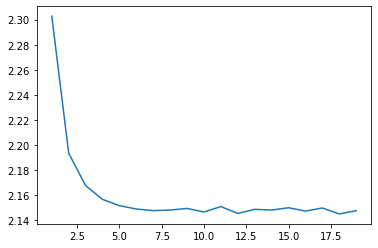

In [14]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.plot(k_list, rmse_knn)

### Сравнение с SVD

In [9]:
algo = SVD(n_factors=10, random_state=999, verbose=False) 
cv=cross_validate(algo, data, measures=['RMSE'], cv=3, verbose=False)
print(np.mean(cv['test_rmse']))

1.8512579892105716


In [10]:
algo = SVD(n_factors=64, random_state=999, verbose=False) 
cv=cross_validate(algo, data, measures=['RMSE'], cv=3, verbose=False)
print(np.mean(cv['test_rmse']))

1.8576312873679994


In [11]:
algo.pu.shape

(87518, 64)

In [12]:
algo.qi.shape

(7045, 64)